# 01 — Exploratory data analysis (HDFS_v1)

Exploration only: every number used in results is produced by `src/` + `scripts/`. Run `make data` first.

In [1]:
import json
import numpy as np
import pandas as pd
from faultaware.utils.config import load_config, project_path
cfg = load_config()
sessions = pd.read_parquet(project_path(cfg.data.sessions_file))
templates = pd.read_csv(project_path(cfg.data.templates_file))
events = pd.read_parquet(project_path(cfg.data.events_file), columns=['block_id', 'ip_id', 'timestamp'])
print(sessions.shape, templates.shape, events.shape)
sessions.head(3)

(541688, 11) (54, 3) (11175629, 3)


,block_id,label,first_ts,last_ts,first_line,n_events,templates,offsets,ips,levels,split
0,-1608999687919862906,0,1226262918,1226266720,0,269,"[0, 1, 0, 0, 2, 2, 3, 3, 2, 3, 4, 4, 4, 5, 0, ...","[0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, ...","[0, 1, 2, 3, 1, 1, 2, 0, 1, 3, 2, 4, 3, 5, 5, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",train
1,7503483334202473044,0,1226262920,1226266722,13,22,"[0, 0, 1, 0, 2, 3, 2, 3, 2, 3, 4, 4, 4, 9, 12,...","[0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 5, 283...","[5, 0, 1, 6, 1, 5, 1, 6, 1, 0, 7, 5, 6, 5, 1, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",train
2,-3544583377289625738,1,1226262921,1226266718,19,223,"[0, 1, 0, 0, 2, 3, 2, 3, 2, 3, 9, 4, 4, 4, 9, ...","[0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 5, ...","[0, 1, 9, 10, 1, 0, 1, 9, 1, 10, 10, 11, 10, 9...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",train


## Class balance per chronological split

In [2]:
sessions.groupby('split')['label'].agg(n='size', anomalies='sum', rate='mean').loc[['train', 'val', 'test']]

,n,anomalies,rate
split,,,
train,402549,13116,0.032582
val,68954,2382,0.034545
test,70185,922,0.013137


Faults are rare (≈1–3.5 %), and the test period has a lower fault rate than train: a real distribution shift that the chronological split exposes (a random split would hide it). Accuracy is therefore never a headline metric.

## Missing values and schema

In [3]:
print(sessions[['block_id','label','first_ts','last_ts','n_events']].isna().sum())
print('unlabelled blocks dropped:', events.block_id.nunique() - len(sessions) - json.loads((project_path(cfg.data.sessions_file).parent / 'split_summary.json').read_text())['n_dropped_gap'])

block_id    0
label       0
first_ts    0
last_ts     0
n_events    0
dtype: int64
unlabelled blocks dropped: 0


## Fault rate over time

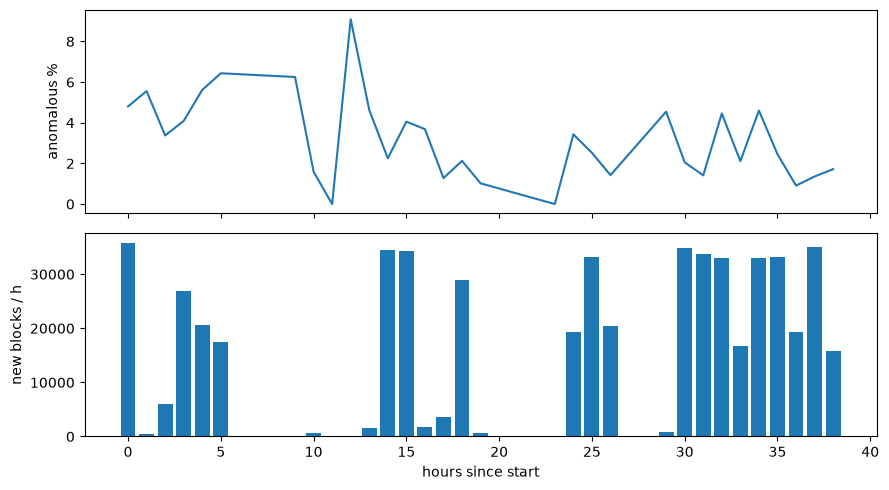

In [4]:
import matplotlib.pyplot as plt
t0 = sessions.first_ts.min()
hour = (sessions.first_ts - t0) // 3600
g = sessions.groupby(hour)['label'].agg(['mean', 'size'])
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
a.plot(g.index, 100 * g['mean']); a.set_ylabel('anomalous %')
b.bar(g.index, g['size']); b.set_ylabel('new blocks / h'); b.set_xlabel('hours since start')
plt.tight_layout()

## Session length and duration by class

In [5]:
sessions.assign(duration_h=(sessions.last_ts - sessions.first_ts) / 3600).groupby('label')[['n_events', 'duration_h']].describe(percentiles=[.5, .9]).T

label                         0             1
n_events   count  525268.000000  16420.000000
           mean       19.697891     17.300183
           std         4.778570     12.436577
           min        13.000000      2.000000
           50%        19.000000     20.000000
           90%        25.000000     31.000000
           max       298.000000    284.000000
duration_h count  525268.000000  16420.000000
           mean        4.957101      4.008131
           std         4.992377      5.134055
           min         0.000000      0.000000
           50%         2.444167      1.461528
           90%        13.466667     13.599694
           max        15.006944     14.978889

Blocks are written within about a minute and deleted hours later, so a 60 s observation window leaves hours of lead time (D-003).

## Per-machine (DataNode IP) distribution

In [6]:
lab = sessions.set_index('block_id')['label']
ev = events.drop_duplicates(['block_id', 'ip_id'])
ev = ev[ev.block_id.isin(lab.index)]
ev['label'] = lab.loc[ev.block_id].to_numpy()
per_ip = ev.groupby('ip_id')['label'].agg(blocks='size', anomaly_rate='mean')
print(per_ip.describe())
per_ip.sort_values('anomaly_rate', ascending=False).head(10)

              blocks  anomaly_rate
count     204.000000    204.000000
mean    10598.210784      0.026689
std     37371.874552      0.021352
min       117.000000      0.016036
25%      7999.500000      0.020230
50%      8060.500000      0.021773
75%      8114.000000      0.027332
max    541688.000000      0.208534


,blocks,anomaly_rate
ip_id,,
148,5601,0.208534
7,7442,0.196856
61,5938,0.140451
111,7136,0.103139
0,117,0.094017
124,7840,0.048342
128,7998,0.042636
39,8052,0.037506
194,8067,0.036197


## Event templates

In [7]:
templates.sort_values('count', ascending=False).head(20)

,template_id,template,count
0,0,INFO dfs.DataNode$DataXceiver: Receiving block...,1723232
4,4,INFO dfs.FSNamesystem: BLOCK* NameSystem.addSt...,1719741
2,2,INFO dfs.DataNode$PacketResponder: PacketRespo...,1706679
3,3,INFO dfs.DataNode$PacketResponder: Received bl...,1706514
16,16,INFO dfs.FSDataset: Deleting block <BLK> file ...,1402047
33,33,INFO dfs.FSNamesystem: BLOCK* NameSystem.delet...,1396174
1,1,INFO dfs.FSNamesystem: BLOCK* NameSystem.alloc...,575061
9,9,INFO dfs.DataNode$DataXceiver: <IP> Served blo...,428726
36,36,WARN dfs.DataNode$DataXceiver: <IP>:Got except...,356207
12,12,INFO dfs.DataBlockScanner: Verification succee...,120036
